# P2P Expense Controls Analytics — San Francisco Vendor Vouchers, FY2025

**Author:** Leon Kitetu Ngumba · github.com/Lkitetu

**Question:** If I ran disbursement controls for a large organization, which payments would I want a human to review first?

**Data:** City and County of San Francisco, *Vendor Payments (Vouchers)*, fiscal year 2025 (July 2024 – June 2025), published by the SF Controller's Office on DataSF (dataset `n9pm-xkyq`). One row per voucher accounting line.

**What this notebook does**
1. Profiles the data and reconciles it down to the spend that is actually *procured or granted* (goods, services, grants), excluding debt service, refunds, taxes, and other non-supplier payments.
2. Classifies every payment by **spending path**: on contract, purchase order without a contract, or direct voucher with no purchase order.
3. Runs **eight control tests**: duplicate payments, near-duplicates, split purchases under the $20K delegated-purchasing limit, recurring use of one-time direct vouchers, round-dollar amounts, Benford's law, period-end spikes, and supplier concentration.
4. Produces a prioritized **exception register** and tables for the Power BI dashboard.

> Every flag is a *lead for review*, not a finding of error or fraud. The public dataset has no invoice numbers or approval records, so a reviewer would confirm each item against source documents.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Looks in ./data first, then the working folder (e.g., files uploaded to Google Colab). Download steps in README.
DATA = next((p for pat in ['data/sf_vouchers*.csv', 'sf_vouchers*.csv'] for p in sorted(Path('.').glob(pat))), None)
assert DATA is not None, 'Put the SF vouchers CSV in ./data or this folder (see README)'
print('Using', DATA)
OUT, CHARTS = Path('output'), Path('charts')
OUT.mkdir(exist_ok=True); CHARTS.mkdir(exist_ok=True)

DELEGATED_LIMIT = 20_000      # SF Prop Q departmental purchasing limit, effective July 1, 2024
DUP_WINDOW_DAYS = 7           # identical payments this close together are review-worthy
DUP_MIN_AMOUNT = 1_000        # ignore small identical amounts (postage, fees)
FY_START, FY_END = '2024-07-01', '2025-06-30'
GENERIC_PAYEES = ['Single Payment Payees']   # catch-all payee name, not a real vendor
# Public agencies, banks and benefit carriers: not procurement relationships (judgment call, documented)
PUBLIC_FIN = (r'STATE OF CALIF|^CITY OF|COUNTY OF|IRRIGATION DISTRICT|UTILITY DISTRICT|WATER DISTRICT|'
              r'POWERS AUTHORITY|TRANSIT AUTHORITY|HOUSING AUTHORITY|BANK|TREAS|BLUE SHIELD|KAISER|CAPITAL LP|ASSET MANAGEMENT|'
              r'SUPERIOR COURT|DEPARTMENT OF|DEPT OF|PUBLIC UTILITY COMMISSION|RAPID TRANSIT DISTRICT')

Using data/sf_vouchers_fy2025.csv


## 1. Load and profile

In [2]:
raw = pd.read_csv(DATA, dtype=str)
for c in ['vouchers_paid', 'vouchers_pending', 'vouchers_pending_retainage']:
    raw[c] = raw[c].astype(float)
raw['date'] = pd.to_datetime(raw['data_as_of'].str[:10])   # voucher posting date

print(f"Rows (voucher accounting lines): {len(raw):,}")
print(f"Distinct vouchers: {raw.voucher.nunique():,} | vendors: {raw.vendor.nunique():,} | departments: {raw.department_code.nunique()}")
print(f"Total paid: ${raw.vouchers_paid.sum()/1e9:,.2f}B")
print(f"Negative lines (credits/reversals): {(raw.vouchers_paid<0).sum():,} | zero-paid lines: {(raw.vouchers_paid==0).sum():,}")

Rows (voucher accounting lines): 515,689
Distinct vouchers: 500,031 | vendors: 6,654 | departments: 56
Total paid: $16.76B
Negative lines (credits/reversals): 4,439 | zero-paid lines: 38,565


## 2. Scope: reconcile total payments to supplier spend

The dataset mixes supplier payments with treasury and liability activity (debt service, tax refunds, deposits returned, benefits). Control tests on procurement only make sense on **third-party spend for goods, services, and grants**, so I reconcile the total down to that scope and keep the excluded amount visible.

In [3]:
GOODS = ['Non-Personnel Services', 'Materials & Supplies', 'Capital Outlay', 'Facilities Maintenance']
GRANTS = ['City Grant Program', 'Other Support/Care of Persons', 'Aid Payments', 'Aid Assistance']
raw['scope'] = np.select([raw.character.isin(GOODS), raw.character.isin(GRANTS)],
                         ['Goods & services', 'Grants & aid'], 'Excluded (non-supplier)')
raw['path'] = np.select([raw.purchase_order.str.startswith('Direct'), raw.contract_number.notna()],
                        ['Direct voucher (no PO)', 'On contract'], 'PO, no contract')

recon = raw.groupby('scope').agg(lines=('voucher', 'size'), paid=('vouchers_paid', 'sum'))
recon.loc['TOTAL'] = recon.sum()
recon['paid_$M'] = recon.paid / 1e6
print(recon[['lines', 'paid_$M']])
excluded_top = (raw[raw.scope.str.startswith('Excluded')].groupby('character').vouchers_paid.sum()
                .sort_values(ascending=False).head(6) / 1e6)
print('\nLargest excluded categories ($M):'); print(excluded_top.round(1))

                             lines   paid_$M
scope                                       
Excluded (non-supplier)  56,521.00  7,922.43
Goods & services        427,509.00  6,709.69
Grants & aid             31,659.00  2,124.92
TOTAL                   515,689.00 16,757.04

Largest excluded categories ($M):
character
Not Reported Liability Account   2,163.40
Debt Service                     1,850.90
Current Liabilities              1,376.60
Fiduciary-Benefit Payments       1,188.40
Other Revenues                     676.20
Business Taxes                     153.40
Name: vouchers_paid, dtype: float64


## 3. Build the voucher-level table

A voucher can be split across several accounting lines (different funds or projects). Duplicate and split tests work on the **voucher**, so I collapse lines to one row per voucher, keeping the accounting string of the largest line.

In [4]:
s = raw[raw.scope != 'Excluded (non-supplier)'].copy()
s = s.sort_values('vouchers_paid', ascending=False)   # 'first' below = largest line
v = (s.groupby('voucher')
       .agg(vendor=('vendor', 'first'), dept=('department_code', 'first'), dept_name=('department', 'first'),
            date=('date', 'min'), po=('purchase_order', 'first'), contract=('contract_number', 'first'),
            path=('path', 'first'), scope=('scope', 'first'), character=('character', 'first'),
            object=('object', 'first'), fund=('fund_code', 'first'), sub_object=('sub_object_code', 'first'),
            amount=('vouchers_paid', 'sum'), lines=('vendor', 'size'), govt_flag=('related_govt_units', 'max'))
       .reset_index())
v['public_or_financial'] = v.vendor.str.upper().str.contains(PUBLIC_FIN, regex=True) | v.govt_flag.eq('YES')
v['generic_payee'] = v.vendor.isin(GENERIC_PAYEES)
v['month'] = v.date.dt.to_period('M').astype(str)
pos = v[v.amount > 0].copy()
vend = pos[~pos.generic_payee]          # vendor-matching tests skip the catch-all payee
print(f"Public-agency / financial payees: {v[v.public_or_financial].vendor.nunique():,} vendors, ${v[v.public_or_financial].amount.sum()/1e6:,.0f}M")
print(f"In-scope vouchers: {len(v):,} | positive: {len(pos):,} | credits: {(v.amount<0).sum():,} | zero: {(v.amount==0).sum():,}")
print(f"In-scope paid: ${v.amount.sum()/1e9:,.2f}B")

Public-agency / financial payees: 302 vendors, $709M
In-scope vouchers: 443,596 | positive: 403,697 | credits: 3,815 | zero: 36,084
In-scope paid: $8.83B


## 4. Spending path: how much spend runs outside contracts?

In [5]:
paths = v.groupby('path').agg(vouchers=('voucher', 'size'), paid=('amount', 'sum'))
paths['share_%'] = 100 * paths.paid / paths.paid.sum()
paths['paid_$M'] = paths.paid / 1e6
print(paths[['vouchers', 'paid_$M', 'share_%']].sort_values('paid_$M', ascending=False))

                        vouchers  paid_$M  share_%
path                                              
On contract               245187 7,989.57    90.43
PO, no contract           132467   458.75     5.19
Direct voucher (no PO)     65942   386.29     4.37


## 5. Control tests

### Test 1 — Duplicate payments
Same vendor, department, purchase order, fund, account, and **identical amount** (≥ $1,000) on different vouchers within 7 days.

Without invoice numbers, some hits are legitimate installments that were processed together. So hits are tiered:
- **Tier A (pair):** exactly two identical vouchers, the classic duplicate pattern. Highest priority.
- **Tier B (batch):** three or more identical vouchers together, more consistent with scheduled installments. Lower priority, still worth a sample review.

In [6]:
key = ['vendor', 'dept', 'po', 'fund', 'sub_object', 'amount']
d = vend[vend.amount >= DUP_MIN_AMOUNT].sort_values(key + ['date']).copy()
d['gap'] = d.groupby(key)['date'].diff().dt.days
d['new_cluster'] = d.gap.isna() | (d.gap > DUP_WINDOW_DAYS)
d['cluster'] = d.new_cluster.cumsum()
size = d.groupby('cluster').voucher.transform('size')
dups = d[size >= 2].copy()
dups['cluster_size'] = size[size >= 2]
dups['tier'] = np.where(dups.cluster_size == 2, 'A - pair', 'B - batch (3+)')
dups['is_repeat'] = ~dups.new_cluster          # first voucher in a cluster is the 'original'

t1 = (dups[dups.is_repeat].groupby('tier')
      .agg(clusters=('cluster', 'nunique'), repeat_vouchers=('voucher', 'size'), repeat_paid=('amount', 'sum')))
print('Potential duplicates (repeat vouchers = amount potentially paid twice):'); print(t1)
print('\nLargest Tier A pairs:')
print(dups[(dups.tier.str.startswith('A')) & dups.is_repeat].nlargest(8, 'amount')[['vendor', 'dept', 'amount', 'date', 'gap', 'po']])

Potential duplicates (repeat vouchers = amount potentially paid twice):
                clusters  repeat_vouchers   repeat_paid
tier                                                   
A - pair            2708             2708 84,219,510.84
B - batch (3+)      1025             3701 86,963,007.91

Largest Tier A pairs:
                                          vendor dept        amount       date  gap            po
325871   REGENTS OF THE UNIVERSITY OF CALIFORNIA  DPH 21,646,221.00 2025-04-02 0.00  000087758701
402847   REGENTS OF THE UNIVERSITY OF CALIFORNIA  DPH 21,646,221.00 2025-05-21 0.00  000087758701
112440      MWH CONSTRS & WEBCOR BLDRS A CNST JV  PUC  1,285,636.00 2024-09-17 5.00  000044738402
356524  UCSF CLINIC PRAC GRP SFGH/COMM FOCUS PGM  DPH  1,118,191.00 2025-04-10 0.00  000087508501
13443                      Mid Market Foundation  ECN  1,041,600.00 2024-06-18 0.00  000076061601
288176                  Alstom Transport USA Inc  AIR    901,825.45 2025-02-24 7.00  00008467

### Test 2 — Near-duplicates
Same vendor, department, and **purchase order**, amounts within **1%** but not identical (≥ $5,000), within 7 days. This is the typical sign of a re-keyed invoice with a small change. Requiring the same PO keeps out construction progress payments split across different funds.

In [7]:
n = vend[vend.amount >= 5_000].sort_values(['vendor', 'dept', 'po', 'amount']).copy()
g = n.groupby(['vendor', 'dept', 'po'])
n['prev_amt'], n['prev_date'], n['prev_voucher'] = g.amount.shift(), g.date.shift(), g.voucher.shift()
n['pct_diff'] = (n.amount - n.prev_amt) / n.prev_amt
n['days'] = (n.date - n.prev_date).dt.days.abs()
near = n[(n.pct_diff > 0) & (n.pct_diff <= 0.01) & (n.days <= DUP_WINDOW_DAYS)].copy()
print(f"Near-duplicate pairs: {len(near):,} | amount on the later voucher: ${near.amount.sum()/1e6:,.2f}M")
print(near.nlargest(6, 'amount')[['vendor', 'dept', 'prev_amt', 'amount', 'pct_diff', 'days']])

Near-duplicate pairs: 2,992 | amount on the later voucher: $114.10M


                                          vendor dept      prev_amt        amount  pct_diff  days
266506                    TURNER CONSTRUCTION CO  AIR 23,256,407.09 23,476,788.50      0.01  0.00
175674             HENSEL PHELPS CONSTRUCTION CO  AIR  2,335,694.00  2,353,714.00      0.01  0.00
313519      MWH CONSTRS & WEBCOR BLDRS A CNST JV  PUC  2,340,622.52  2,348,599.25      0.00  2.00
89552   UCSF CLINIC PRAC GRP SFGH/COMM FOCUS PGM  DPH  1,074,505.80  1,080,384.75      0.01  1.00
2589                       PCL CONSTRUCTION INC.  PUC  1,079,817.85  1,080,078.29      0.00  0.00
179188                 MARK CAVAGNERO ASSOCIATES  PUC  1,024,520.63  1,029,114.86      0.00  0.00


### Test 3 — Split purchases under the $20,000 delegated-purchasing limit
SF departments can buy up to **$20,000** on their own (Prop Q, effective July 1, 2024), and **splitting orders to stay under the limit is prohibited**. I look for purchases *not on a contract* (non-contract POs and direct vouchers) where the same department bought from the same vendor in **2–5 separate documents within 14 days, each between $10K and $20K (just under the limit), that together exceed $20K**.

The $10K floor and the 5-document cap keep out routine high-volume buying (for example, daily medical-supply orders), which is a different issue from deliberate splitting.

In [8]:
nc = vend[vend.path != 'On contract'].copy()
nc['doc'] = np.where(nc.path.str.startswith('Direct'), 'DV-' + nc.voucher, 'PO-' + nc.po)
docs = (nc.groupby(['dept', 'vendor', 'doc'])
          .agg(doc_amount=('amount', 'sum'), doc_date=('date', 'min'), vouchers=('voucher', list))
          .reset_index())
docs = docs[(docs.doc_amount >= DELEGATED_LIMIT / 2) & (docs.doc_amount < DELEGATED_LIMIT)].sort_values(['dept', 'vendor', 'doc_date'])

hits = []
for (dept, vendor), grp in docs.groupby(['dept', 'vendor']):
    if len(grp) < 2: continue
    dates, amts, ids = grp.doc_date.values, grp.doc_amount.values, grp.index.values
    i = 0
    while i < len(grp):
        j = i
        while j + 1 < len(grp) and (dates[j+1] - dates[i]) <= np.timedelta64(14, 'D'): j += 1
        if 1 <= j - i <= 4 and amts[i:j+1].sum() > DELEGATED_LIMIT:
            hits.append((dept, vendor, j - i + 1, amts[i:j+1].sum(), dates[i], list(ids[i:j+1])))
            i = j + 1
        elif j - i > 4:      # 6+ documents in 14 days = high-volume buying, not splitting
            i = j + 1
        else:
            i += 1
splits = pd.DataFrame(hits, columns=['dept', 'vendor', 'documents', 'combined_amount', 'first_date', 'doc_rows'])
split_vouchers = docs.loc[[r for rows in splits.doc_rows for r in rows], 'vouchers'].explode()
print(f"Potential split-purchase clusters: {len(splits):,} | documents: {splits.documents.sum():,} | combined: ${splits.combined_amount.sum()/1e6:,.2f}M")
print(splits.nlargest(8, 'combined_amount')[['dept', 'vendor', 'documents', 'combined_amount', 'first_date']])

Potential split-purchase clusters: 460 | documents: 1,175 | combined: $17.43M
    dept                         vendor  documents  combined_amount first_date
60   ADM              ROLLING STOCK INC          5        98,856.43 2025-04-02
279  FIR        UCSF/SFGH MEDICAL GROUP          5        94,910.56 2025-05-01
365  MTA             VORTECH INDUSTRIES          5        80,243.83 2025-02-10
414  PUC   LANER ELECTRIC SUPPLY CO INC          5        79,893.26 2024-11-21
51   ADM              ROLLING STOCK INC          4        79,735.64 2024-07-16
366  MTA             VORTECH INDUSTRIES          5        78,707.28 2025-02-26
53   ADM              ROLLING STOCK INC          4        78,385.44 2024-08-22
370  POL  BLAISDELL'S BUSINESS PRODUCTS          5        77,855.71 2024-09-23


### Test 4 — Recurring use of one-time direct vouchers
SF's own data notes say direct voucher payments are for **"limited one-time, non-recurring payments (e.g., a membership or a subscription)."** A vendor paid by direct voucher in many separate months is recurring spend that bypasses purchase orders and contracts.

Flag: vendor–department pairs paid by direct voucher in **6+ distinct months** totaling **$50K+**, excluding public agencies, banks, and benefit carriers. Payments to those are intergovernmental or financial transfers, not purchases.

In [9]:
dv = vend[vend.path.str.startswith('Direct') & ~vend.public_or_financial]
rec = (dv.groupby(['dept', 'dept_name', 'vendor'])
         .agg(months=('month', 'nunique'), vouchers=('voucher', 'size'), paid=('amount', 'sum'))
         .reset_index())
recurring = rec[(rec.months >= 6) & (rec.paid >= 50_000)].sort_values('paid', ascending=False)
print(f"Direct-voucher spend in scope: ${dv.amount.sum()/1e6:,.1f}M across {dv.vendor.nunique():,} vendors")
print(f"Recurring direct-voucher relationships: {len(recurring):,} | spend: ${recurring.paid.sum()/1e6:,.1f}M "
      f"({100*recurring.paid.sum()/dv.amount.sum():.0f}% of direct-voucher spend)")
print(recurring.head(10)[['dept', 'vendor', 'months', 'vouchers', 'paid']])

Direct-voucher spend in scope: $102.3M across 1,756 vendors
Recurring direct-voucher relationships: 145 | spend: $51.6M (50% of direct-voucher spend)
     dept                                    vendor  months  vouchers         paid
1196  DPH          RICHMOND AREA MULTI-SERVICES INC      12        73 7,308,642.91
1605  MTA                             CityBase Inc.      12        60 4,227,930.97
1105  DPH                          FELTON INSTITUTE       9        43 2,420,706.99
1948  PUC                  BEVERIDGE & DIAMOND P.C.       8        58 2,327,222.74
2198  SCI            CALIFORNIA ACADEMY OF SCIENCES      11        36 2,049,556.00
1073  DPH                          CONARD HOUSE INC       7        11 1,896,212.73
1094  DPH  EDGEWOOD CENTER FOR CHILDREN AND FAMILES       6        15 1,128,341.53
1264  DPW                 PACIFIC GAS & ELECTRIC CO      11       107 1,113,900.69
2031  PUC             LIBKRA INVESTMENT CORPORATION      12        12 1,089,487.78
1118  DPH           

### Test 5 — Round-dollar payments outside contracts
Exact multiples of $1,000 at $10,000 or more, on payments **not tied to a contract**. Round amounts are normal for contract installments and grants, but on ad hoc purchases they can indicate estimates rather than invoices.

In [10]:
rd = vend[(vend.path != 'On contract') & (vend.amount >= 10_000) & (np.isclose(vend.amount % 1000, 0))].copy()
print(f"Round-dollar non-contract payments: {len(rd):,} | ${rd.amount.sum()/1e6:,.2f}M")
print(rd.groupby('path').amount.agg(['count', 'sum']))

Round-dollar non-contract payments: 297 | $18.34M
                        count           sum
path                                       
Direct voucher (no PO)    170 10,148,000.00
PO, no contract           127  8,194,000.00


### Test 6 — Benford's law (first-digit test)
In naturally occurring financial data, the leading digit is 1 about 30% of the time and 9 under 5%. Large deviations can point to fabricated or threshold-driven amounts. I use **Mean Absolute Deviation (MAD)** with Nigrini's first-digit thresholds: < 0.006 close, 0.006–0.012 acceptable, 0.012–0.015 marginal, > 0.015 **nonconformity**.

In [11]:
benford = np.log10(1 + 1 / np.arange(1, 10))
def first_digit(x): return (x / 10 ** np.floor(np.log10(x))).astype(int)
b = pos[pos.amount >= 10].copy()
b['fd'] = first_digit(b.amount.values)
def mad(series):
    obs = series.value_counts(normalize=True).reindex(range(1, 10), fill_value=0).values
    return np.abs(obs - benford).mean(), obs
overall_mad, overall_obs = mad(b.fd)
print(f"Overall MAD: {overall_mad:.4f}")

rows = []
for (dept, name), grp in b.groupby(['dept', 'dept_name']):
    if len(grp) < 1000: continue
    m, obs = mad(grp.fd)
    excess = obs - benford
    rows.append((dept, name, len(grp), m, int(np.argmax(excess)) + 1, excess.max()))
bdept = pd.DataFrame(rows, columns=['dept', 'dept_name', 'vouchers', 'MAD', 'most_overused_digit', 'excess_share'])
bdept['conformity'] = pd.cut(bdept.MAD, [0, .006, .012, .015, 1], labels=['Close', 'Acceptable', 'Marginal', 'Nonconformity'])
print(bdept.sort_values('MAD', ascending=False).head(10))
print('\nDepartments by conformity:', bdept.conformity.value_counts().to_dict())

Overall MAD: 0.0025


   dept                      dept_name  vouchers  MAD  most_overused_digit  excess_share     conformity
24  REG                  REG Elections      3682 0.13                    2          0.57  Nonconformity
27  TTX    TTX Treasurer-Tax Collector      2596 0.05                    1          0.18  Nonconformity
2   ART            ART Arts Commission      1717 0.03                    2          0.13  Nonconformity
7   DEC    DEC Dept of Early Childhood      1197 0.03                    6          0.03  Nonconformity
3   CAT              CAT City Attorney      5410 0.03                    8          0.07  Nonconformity
20  POL                     POL Police      8011 0.03                    1          0.13  Nonconformity
4   CHF  CHF Children;Youth & Families      3754 0.02                    3          0.04  Nonconformity
6   DAT          DAT District Attorney      1824 0.02                    4          0.03  Nonconformity
8   DEM       DEM Emergency Management      1698 0.02           

### Test 7 — Period-end spending
Departments that rush to spend budget before the fiscal year closes on **June 30** show a June spike. I compare June 2025 to the July–May monthly average. Payments the dataset dates outside July 2024–June 2025 are excluded here; they reflect payments made later against FY2025 budget lines.

In [12]:
inper = v[(v.date >= FY_START) & (v.date <= FY_END)]
monthly = inper.groupby('month').amount.sum() / 1e6
june = monthly.loc['2025-06']; base = monthly.drop('2025-06').mean()
print(monthly.round(1))
print(f"\nJune 2025: ${june:,.0f}M vs Jul–May average ${base:,.0f}M  ->  {100*(june/base-1):+.0f}%")
out_of_window = v[(v.date < FY_START) | (v.date > FY_END)]
print(f"Vouchers dated outside Jul 2024–Jun 2025: {len(out_of_window):,} (${out_of_window.amount.sum()/1e6:,.0f}M)")

dept_june = (inper.assign(is_june=inper.month.eq('2025-06'))
             .groupby(['dept', 'dept_name', 'is_june']).amount.sum().unstack(fill_value=0))
dept_june.columns = ['jul_may', 'june']
dept_june['june_vs_avg_%'] = 100 * (dept_june.june / (dept_june.jul_may / 11) - 1)
spikes = dept_june[(dept_june.june >= 5e6)].sort_values('june_vs_avg_%', ascending=False)
print(spikes.head(8).round(0))

month
2024-07   842.80
2024-08   655.80
2024-09   536.20
2024-10   658.70
2024-11   578.70
2024-12   722.30
2025-01   733.90
2025-02   742.50
2025-03   596.90
2025-04   685.50
2025-05   589.30
2025-06   518.80
Name: amount, dtype: float64

June 2025: $519M vs Jul–May average $667M  ->  -22%
Vouchers dated outside Jul 2024–Jun 2025: 21,163 ($973M)


                                             jul_may           june  june_vs_avg_%
dept dept_name                                                                    
REC  REC Recreation & Park Commsn      51,881,825.00   8,901,201.00          89.00
ECN  ECN Economic & Wrkfrce Dvlpmnt    89,092,461.00  10,501,241.00          30.00
PUC  PUC Public Utilities Commsn    1,643,342,970.00 142,949,656.00          -4.00
CHF  CHF Children;Youth & Families    124,947,390.00  10,087,973.00         -11.00
MYR  MYR Mayor                        446,041,418.00  33,216,771.00         -18.00
HOM  HOM Homelessness Services        488,578,878.00  35,486,368.00         -20.00
DPH  DPH Public Health              1,333,628,966.00  93,565,895.00         -23.00
AIR  AIR Airport Commission           717,290,412.00  49,360,262.00         -24.00


### Test 8 — Supplier concentration by spend category
Procurement teams manage spend by **category** (engineering services, IT software, medical supplies), not by department. Where one supplier wins most of a category citywide, the City carries dependency risk, and it's also where competitive sourcing or renegotiation has the most leverage.

I measure each category's top-supplier share and the **Herfindahl-Hirschman Index (HHI)**: above 1,500 is moderately concentrated, above 2,500 highly concentrated. Scope: goods & services categories with at least $10M of spend, excluding public agencies, banks, and benefit carriers.

In [13]:
gs = vend[(vend.scope == 'Goods & services') & ~vend.public_or_financial].merge(
        s.drop_duplicates('voucher')[['voucher', 'sub_object']].rename(columns={'sub_object': 'category'}), on='voucher')
gs = gs[~gs.category.isin(['Taxes', 'Payments To Other Govt'])]   # pass-through, not sourceable spend
vs = gs.groupby(['category', 'vendor']).amount.sum().reset_index()
vs['share'] = vs.amount / vs.groupby('category').amount.transform('sum')
conc = (vs.sort_values('share', ascending=False).groupby('category')
          .agg(spend=('amount', 'sum'), vendors=('vendor', 'size'), top_vendor=('vendor', 'first'),
               top1_share=('share', 'first'), top3_share=('share', lambda x: x.head(3).sum()),
               HHI=('share', lambda x: (100 * x).pow(2).sum()))
          .reset_index())
conc['level'] = pd.cut(conc.HHI, [0, 1500, 2500, 10001], labels=['Competitive', 'Moderate', 'High'])
big = conc[conc.spend >= 10e6]
conc_flag = big[big.HHI > 2500].sort_values('spend', ascending=False)
print(f"Categories with >= $10M spend: {len(big)} | highly concentrated (HHI > 2,500): {len(conc_flag)} "
      f"covering ${conc_flag.spend.sum()/1e6:,.0f}M ({100*conc_flag.spend.sum()/big.spend.sum():.0f}% of that spend)")
print(conc_flag[['category', 'spend', 'vendors', 'top_vendor', 'top1_share', 'top3_share', 'HHI']].head(12))

Categories with >= $10M spend: 55 | highly concentrated (HHI > 2,500): 15 covering $956M (16% of that spend)
                           category          spend  vendors                               top_vendor  top1_share  top3_share       HHI
190             UC Medical Services 290,171,448.06        5  REGENTS OF THE UNIVERSITY OF CALIFORNIA        0.99        1.00  9,853.46
14      Automotive & Other Vehicles 177,154,042.58       44                    Siemens Mobility Inc.        0.78        0.87  6,140.96
139                  Pharmaceutical 138,957,583.77       26                     MCKESSON CORPORATION        0.63        0.98  5,007.59
144      Power Distrib Transmission  57,800,472.08        6                                A P X INC        0.49        0.99  4,671.15
192   Veh Maint (Non Central Shops)  50,292,674.93      109                     COMPLETE COACH WORKS        0.85        0.90  7,285.64
70                Insurance Expense  49,750,164.54        5           ALLIANT INS

## 6. Exception register and risk score

Each voucher gets points for every test it trips, plus points for size, so reviewers start with the highest-risk dollars. Weights are a judgment call, and they're documented here so they can be challenged.

In [14]:
W = {'T1 Duplicate - pair': 40, 'T1 Duplicate - batch': 15, 'T2 Near-duplicate': 25,
     'T3 Split purchase': 30, 'T4 Recurring direct voucher': 20, 'T5 Round-dollar (non-contract)': 10}
ex = []
dups['original_voucher'] = dups.groupby('cluster').voucher.transform('first')
a = dups[dups.is_repeat]
ex.append(pd.DataFrame({'voucher': a.voucher, 'test': np.where(a.tier.str.startswith('A'), 'T1 Duplicate - pair', 'T1 Duplicate - batch'),
                        'reason': 'Identical to voucher ' + a.original_voucher + ' (same vendor, PO, fund, account) within ' + a.gap.astype(int).astype(str) + ' days'}))
ex.append(pd.DataFrame({'voucher': near.voucher, 'test': 'T2 Near-duplicate',
                        'reason': 'Within ' + (100*near.pct_diff).round(2).astype(str) + '% of voucher ' + near.prev_voucher}))
ex.append(pd.DataFrame({'voucher': split_vouchers.values, 'test': 'T3 Split purchase',
                        'reason': 'Part of sub-$20K documents to one vendor totaling over $20K within 14 days'}))
rv = dv.merge(recurring[['dept', 'vendor', 'months']], on=['dept', 'vendor'])
ex.append(pd.DataFrame({'voucher': rv.voucher, 'test': 'T4 Recurring direct voucher',
                        'reason': 'Direct voucher to vendor paid this way in ' + rv.months.astype(str) + ' months'}))
ex.append(pd.DataFrame({'voucher': rd.voucher, 'test': 'T5 Round-dollar (non-contract)', 'reason': 'Exact multiple of $1,000'}))
exceptions = pd.concat(ex, ignore_index=True).drop_duplicates(['voucher', 'test'])
exceptions = exceptions.merge(v[['voucher', 'vendor', 'dept', 'dept_name', 'date', 'path', 'amount']], on='voucher')
exceptions['test_points'] = exceptions.test.map(W)

score = exceptions.groupby('voucher').test_points.sum()
amt = v.set_index('voucher').amount
size_pts = np.select([amt >= 100_000, amt >= 10_000], [20, 10], 0)
size_pts = pd.Series(size_pts, index=amt.index)
exceptions['risk_score'] = exceptions.voucher.map(score) + exceptions.voucher.map(size_pts)
exceptions = exceptions.sort_values(['risk_score', 'amount'], ascending=False)

summary = (exceptions.groupby('test').agg(vouchers=('voucher', 'nunique'), amount=('amount', 'sum'))
           .reindex(list(W)))
flagged = exceptions.drop_duplicates('voucher')
print(summary.assign(amount_M=summary.amount/1e6)[['vouchers', 'amount_M']])
print(f"\nUnique flagged vouchers: {flagged.voucher.nunique():,} | ${flagged.amount.sum()/1e6:,.1f}M "
      f"| {100*flagged.voucher.nunique()/len(pos):.1f}% of positive in-scope vouchers")
print(f"Flagged by 2+ tests: {(exceptions.groupby('voucher').size() >= 2).sum():,}")
print(exceptions.head(10)[['voucher', 'vendor', 'dept', 'amount', 'test', 'risk_score']])

                                vouchers  amount_M
test                                              
T1 Duplicate - pair                 2708     84.22
T1 Duplicate - batch                3701     86.96
T2 Near-duplicate                   2992    114.10
T3 Split purchase                   6280     17.43
T4 Recurring direct voucher         7735     51.58
T5 Round-dollar (non-contract)       297     18.34

Unique flagged vouchers: 23,277 | $367.8M | 5.8% of positive in-scope vouchers
Flagged by 2+ tests: 422
          voucher                         vendor dept    amount                         test  risk_score
5890   0307666801                THOMSON REUTERS  CAT 16,743.57          T1 Duplicate - pair         100
13100  0307666801                THOMSON REUTERS  CAT 16,743.57            T3 Split purchase         100
16755  0307666801                THOMSON REUTERS  CAT 16,743.57  T4 Recurring direct voucher         100
6046   0313916301       Three BG Investments LLC  PUC 14,101.50    

## 7. Export tables for Power BI and the README

In [15]:
fact = v[['voucher', 'date', 'month', 'dept', 'dept_name', 'vendor', 'path', 'scope', 'character', 'object', 'po', 'contract', 'amount']]
fact = fact.assign(is_flagged=fact.voucher.isin(exceptions.voucher))
fact.to_csv(OUT / 'fact_payments.csv', index=False)
exceptions.to_csv(OUT / 'exceptions.csv', index=False)
summary.reset_index().to_csv(OUT / 'summary_by_test.csv', index=False)
conc.sort_values('spend', ascending=False).to_csv(OUT / 'supplier_concentration.csv', index=False)
bdept.to_csv(OUT / 'benford_by_department.csv', index=False)
recurring.to_csv(OUT / 'recurring_direct_vouchers.csv', index=False)
splits.drop(columns='doc_rows').to_csv(OUT / 'split_purchase_clusters.csv', index=False)
paths.reset_index().to_csv(OUT / 'spend_by_path.csv', index=False)
monthly.reset_index().rename(columns={'amount': 'paid_$M'}).to_csv(OUT / 'monthly_spend.csv', index=False)
print(sorted(p.name for p in OUT.iterdir()))

['benford_by_department.csv', 'exceptions.csv', 'fact_payments.csv', 'fact_payments.zip', 'headline.json', 'monthly_spend.csv', 'recurring_direct_vouchers.csv', 'spend_by_path.csv', 'split_purchase_clusters.csv', 'summary_by_test.csv', 'supplier_concentration.csv']


## 8. Charts

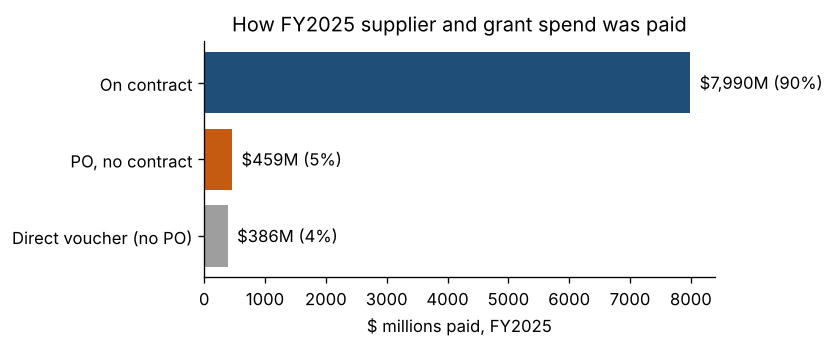

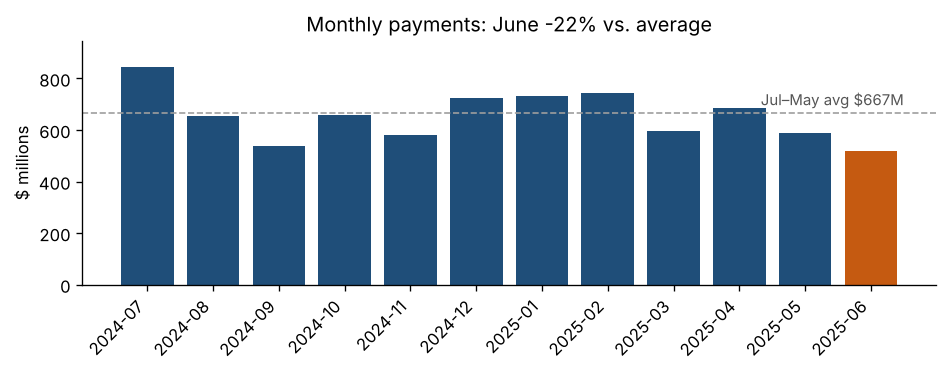

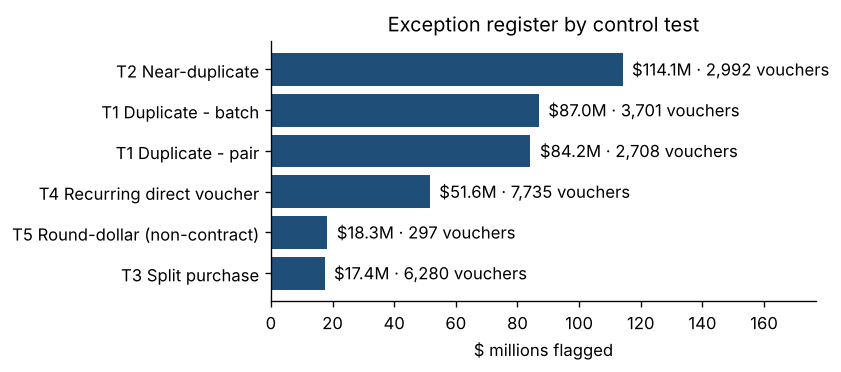

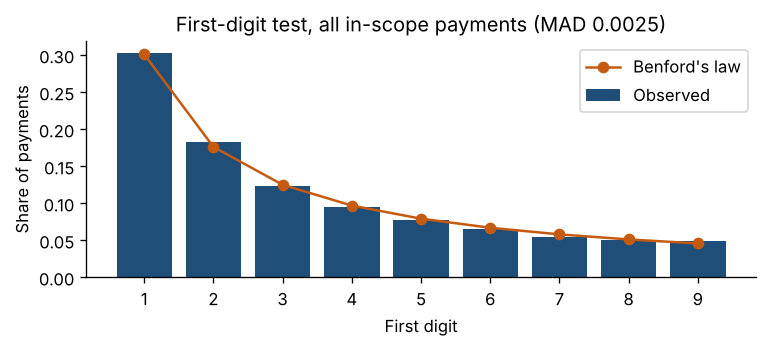

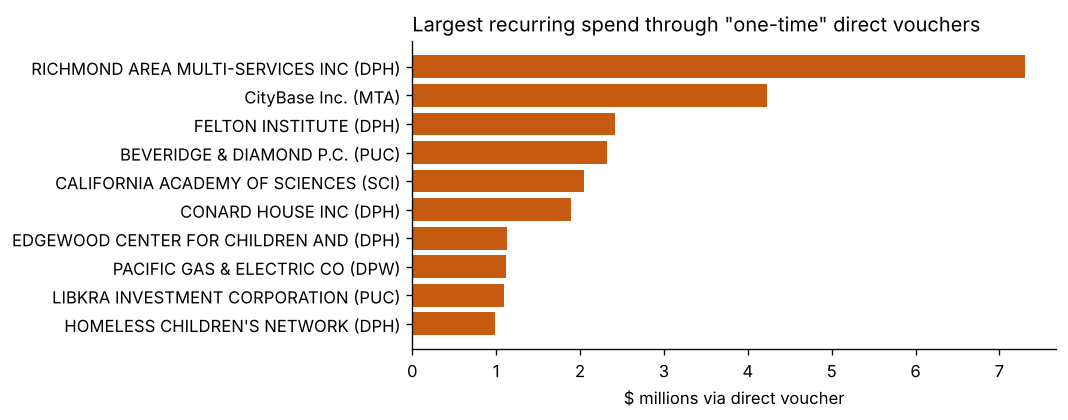

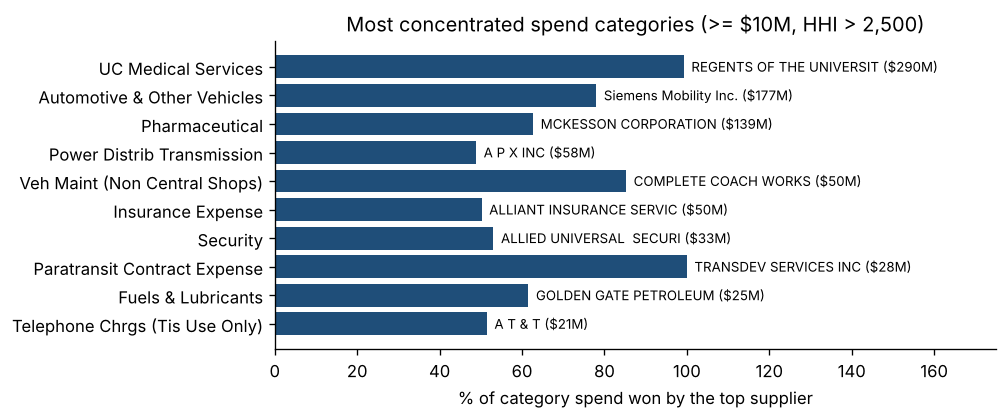

In [16]:
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
C1, C2, GREY = '#1f4e79', '#c55a11', '#9e9e9e'

# 1. Spend by path
fig, ax = plt.subplots(figsize=(7, 3))
p = paths.sort_values('paid_$M')
ax.barh(p.index, p['paid_$M'], color=[GREY, C2, C1][:len(p)])
for i, (val, sh) in enumerate(zip(p['paid_$M'], p['share_%'])): ax.text(val, i, f'  ${val:,.0f}M ({sh:.0f}%)', va='center')
ax.set_xlabel('$ millions paid, FY2025'); ax.set_title('How FY2025 supplier and grant spend was paid')
plt.tight_layout(); plt.savefig(CHARTS / '01_spend_by_path.png'); plt.show()

# 2. Monthly spend with June highlighted
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(monthly.index, monthly.values, color=[C2 if m == '2025-06' else C1 for m in monthly.index])
ax.axhline(base, color=GREY, ls='--', lw=1); ax.text(len(monthly) - 0.5, base + 15, f'Jul–May avg ${base:,.0f}M', ha='right', va='bottom', color='#555', fontsize=9)
ax.set_ylim(0, monthly.max() * 1.12)
ax.set_ylabel('$ millions'); ax.set_title(f'Monthly payments: June {100*(june/base-1):+.0f}% vs. average')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.savefig(CHARTS / '02_monthly_spend.png'); plt.show()

# 3. Flagged $ by test
fig, ax = plt.subplots(figsize=(7, 3.2))
sm = summary.assign(M=summary.amount / 1e6).sort_values('M')
ax.barh(sm.index, sm.M, color=C1)
for i, (m, n_) in enumerate(zip(sm.M, sm.vouchers)): ax.text(m, i, f'  ${m:,.1f}M · {n_:,} vouchers', va='center')
ax.set_xlim(0, sm.M.max() * 1.55); ax.set_xlabel('$ millions flagged'); ax.set_title('Exception register by control test')
plt.tight_layout(); plt.savefig(CHARTS / '03_flagged_by_test.png'); plt.show()

# 4. Benford overall
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(range(1, 10), overall_obs, color=C1, label='Observed')
ax.plot(range(1, 10), benford, 'o-', color=C2, label="Benford's law")
ax.set_xticks(range(1, 10)); ax.set_xlabel('First digit'); ax.set_ylabel('Share of payments')
ax.set_title(f'First-digit test, all in-scope payments (MAD {overall_mad:.4f})'); ax.legend()
plt.tight_layout(); plt.savefig(CHARTS / '04_benford.png'); plt.show()

# 5. Recurring direct vouchers: top relationships
fig, ax = plt.subplots(figsize=(9, 3.6))
top = recurring.head(10).iloc[::-1]
ax.barh(top.vendor.str[:32] + ' (' + top.dept + ')', top.paid / 1e6, color=C2)
ax.set_xlabel('$ millions via direct voucher'); ax.set_title('Largest recurring spend through "one-time" direct vouchers', loc='left')
plt.tight_layout(); plt.savefig(CHARTS / '05_recurring_direct_vouchers.png'); plt.show()

# 6. Concentration by category
fig, ax = plt.subplots(figsize=(8.5, 3.6))
cf = conc_flag.head(10).iloc[::-1]
ax.barh(cf.category.str[:34], 100 * cf.top1_share, color=C1)
for i, (sh, vname, sp) in enumerate(zip(cf.top1_share, cf.top_vendor, cf.spend)):
    ax.text(100 * sh, i, f'  {vname[:24]} (${sp/1e6:,.0f}M)', va='center', fontsize=8)
ax.set_xlabel('% of category spend won by the top supplier'); ax.set_xlim(0, 175)
ax.set_title('Most concentrated spend categories (>= $10M, HHI > 2,500)')
plt.tight_layout(); plt.savefig(CHARTS / '06_concentration.png'); plt.show()

## 9. Headline numbers

In [17]:
headline = {
    'in_scope_vouchers': len(v),
    'in_scope_paid_$B': round(v.amount.sum() / 1e9, 2),
    'unique_flagged_vouchers': int(flagged.voucher.nunique()),
    'flagged_$M': round(flagged.amount.sum() / 1e6, 1),
    'tierA_duplicate_pairs': int((dups.is_repeat & dups.tier.str.startswith('A')).sum()),
    'tierA_duplicate_$M': round(dups[dups.is_repeat & dups.tier.str.startswith('A')].amount.sum() / 1e6, 2),
    'split_clusters': len(splits),
    'recurring_direct_relationships': len(recurring),
    'recurring_direct_$M': round(recurring.paid.sum() / 1e6, 1),
    'june_vs_avg_%': round(100 * (june / base - 1), 0),
    'benford_overall_MAD': round(overall_mad, 4),
    'concentrated_categories': len(conc_flag),
    'concentrated_category_spend_$M': round(conc_flag.spend.sum() / 1e6, 0),
    'direct_voucher_test4_scope_$M': round(dv.amount.sum() / 1e6, 1),
    'off_contract_$M': round(v[v.path != 'On contract'].amount.sum() / 1e6, 1),
    'off_contract_share_%': round(100 * v[v.path != 'On contract'].amount.sum() / v.amount.sum(), 1),
}
pd.Series(headline).to_json(OUT / 'headline.json', indent=2)
pd.Series(headline)

in_scope_vouchers                443,596.00
in_scope_paid_$B                       8.83
unique_flagged_vouchers           23,277.00
flagged_$M                           367.80
tierA_duplicate_pairs              2,708.00
tierA_duplicate_$M                    84.22
split_clusters                       460.00
recurring_direct_relationships       145.00
recurring_direct_$M                   51.60
june_vs_avg_%                        -22.00
benford_overall_MAD                    0.00
concentrated_categories               15.00
concentrated_category_spend_$M       956.00
direct_voucher_test4_scope_$M        102.30
off_contract_$M                      845.00
off_contract_share_%                   9.60
dtype: float64